# T01 · Fondements : perceptron, descente de gradient, backpropagation — DL/RL appliqués à la cybersécurité

**Objectifs du cours :**
- Comprendre le perceptron, la séparabilité linéaire et pourquoi XOR exige un réseau à couches cachées
- Maîtriser activations, fonctions de perte et descente de gradient (full-batch / mini-batch, choix du pas)
- Écrire à la main la rétropropagation d'un MLP en numpy et la **vérifier** par gradient check numérique

**Pourquoi c'est fondamental en cyber :**

| Besoin cyber | Outil |
|---|---|
| Détecteur de scan de ports / brute force | Classifieur binaire entraîné par gradient (P4, P6) |
| Pourquoi mon détecteur ne voit-il pas cette classe d'attaque ? | Séparabilité linéaire, XOR (P1) |
| Comprendre tout framework DL (PyTorch, TF) | Backprop = règle de la chaîne (P5) |
| Métrique fiable d'un détecteur | Entropie croisée, précision/rappel (P3, P6) |

**Pré-requis :** dérivées et règle de la chaîne (T03 du module maths), algèbre matricielle de base, `numpy`.

> 💡 *Conseil étude* : exécutez chaque cellule, modifiez les graines et les
> hyperparamètres, prédisez la sortie **avant** de l'observer. Ici, tout est
> réimplémenté à la main : c'est en écrivant le backward qu'on le comprend.


## 📌 Bloc 0 — Environnement & imports
Installez le stack si besoin (déjà pré-installé sur Colab).
Chaque notebook contient des sorties pré-calculées : vous pouvez les relire
sans rien exécuter, ou « Run All » pour reproduire.

In [1]:
!pip install -q numpy scipy pandas matplotlib scikit-learn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss, roc_auc_score, precision_score, recall_score
np.set_printoptions(precision=3, suppress=True, linewidth=100)
print("numpy", np.__version__)

error: externally-managed-environment

× This environment is externally managed
╰─> To install Python packages system-wide, try apt install
    python3-xyz, where xyz is the package you are trying to
    install.
    
    If you wish to install a non-Debian-packaged Python package,
    create a virtual environment using python3 -m venv path/to/venv.
    Then use path/to/venv/bin/python and path/to/venv/bin/pip. Make
    sure you have python3-full installed.
    
    If you wish to install a non-Debian packaged Python application,
    it may be easiest to use pipx install xyz, which will manage a
    virtual environment for you. Make sure you have pipx installed.
    
    See /usr/share/doc/python3.12/README.venv for more information.

note: If you believe this is a mistake, please contact your Python installation or OS distribution provider. You can override this, at the risk of breaking your Python installation or OS, by passing --break-system-packages.
hint: See PEP 668 for the detai

numpy 2.5.4


## 1 · Le perceptron & la séparabilité linéaire (XOR)

### Ce qu'on apprend
Le **perceptron** (Rosenblatt, 1958) est une unité linéaire à seuil :

```
ŷ = 1{ w·x + b ≥ 0 }
```

Règle d'apprentissage : sur chaque exemple mal classé,
`w ← w + η (y − ŷ) x` et `b ← b + η (y − ŷ)`.
Le **théorème de convergence du perceptron** garantit la convergence en un
nombre fini d'erreurs **si et seulement si les données sont séparables
linéairement**.

- AND, OR : séparables → le perceptron converge.
- **XOR : non séparable** → aucune droite ne sépare les deux classes. C'est la
  limite historique (Minsky & Papert, 1969) qui a forcé l'ajout de **couches
  cachées** : un MLP avec une couche cachée + activation non linéaire résout XOR.

### Piège classique
Un détecteur « linéaire » (régression logistique, perceptron) sur des features
brutes échoue dès que les attaques occupent deux régions disjoints du domaine
(« login normal de jour » **ou** « login normal de nuit » mais pas le mélange).
Sans couche cachée, pas de frontière non linéaire.


AND : convergé à l'époque 6  poids = [2. 1.] b = -3.0
XOR : convergé ? None  meilleure exactitude par époque = 0.5
-> le perceptron ne JAMAIS séparé XOR : il faut une couche cachée (voir P5).


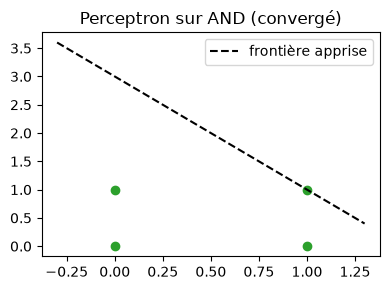

In [2]:
def perceptron_fit(X, y, lr=1.0, max_epochs=100):
    """Train a single-layer perceptron; return weights, convergence epoch, best epoch-accuracy."""
    w = np.zeros(X.shape[1]); b = 0.0
    best_acc = 0.0; converged_at = None
    for ep in range(max_epochs):
        errs = 0
        for i in range(len(y)):
            pred = int((X[i] @ w + b) >= 0)
            if pred != y[i]:
                errs += 1
                w += lr * (y[i] - pred) * X[i]
                b += lr * (y[i] - pred)
        acc = np.mean((X @ w + b >= 0).astype(int) == y)
        best_acc = max(best_acc, acc)
        if errs == 0 and converged_at is None:
            converged_at = ep + 1
            break
    return w, b, converged_at, best_acc

X4 = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
w_and, b_and, conv_and, best_and = perceptron_fit(X4, np.array([0., 0., 0., 1.]))
print("AND : convergé à l'époque", conv_and, " poids =", w_and, "b =", b_and)

w_xor, b_xor, conv_xor, best_xor = perceptron_fit(X4, np.array([0., 1., 1., 0.]))
print("XOR : convergé ?", conv_xor, " meilleure exactitude par époque =", best_xor)
print("-> le perceptron ne JAMAIS séparé XOR : il faut une couche cachée (voir P5).")

# frontière apprise pour AND, pour visualiser
xx = np.linspace(-0.3, 1.3, 50)
yy_line = (-w_and[0] * xx - b_and) / w_and[1] if abs(w_and[1]) > 1e-9 else xx * 0
plt.figure(figsize=(4, 3))
for i, pt in enumerate(X4):
    plt.plot(*pt, "o", color="tab:green" if (X4 @ w_and + b_and >= 0)[i] == (np.array([0,0,0,1])[i]) else "tab:red")
plt.plot(xx, yy_line, "k--", label="frontière apprise")
plt.title("Perceptron sur AND (convergé)"); plt.legend(); plt.tight_layout(); plt.show()

### Exercice corrigé

In [3]:
# ---- Exercice P1 : perceptron sur AND converge, échoue sur XOR ----
X4 = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
y_and = np.array([0., 0., 0., 1.])
y_xor = np.array([0., 1., 1., 0.])

# 1) AND doit converger en 6 époques (valeur sondée) et tout classer
w, b, conv, best = perceptron_fit(X4, y_and)
acc_and = np.mean((X4 @ w + b >= 0).astype(int) == y_and)
print(f"AND : converged_at = {conv}, exactitude = {acc_and}")
assert conv == 6
assert acc_and == 1.0

# 2) XOR ne converge jamais en 100 époques et plafonne loin de 100 %
w2, b2, conv2, best2 = perceptron_fit(X4, y_xor)
print(f"XOR : converged_at = {conv2}, meilleure exactitude = {best2}")
assert conv2 is None
assert best2 < 0.75
print("Exercice P1 vérifié : AND séparable, XOR non séparable par perceptron.")

AND : converged_at = 6, exactitude = 1.0
XOR : converged_at = None, meilleure exactitude = 0.5
Exercice P1 vérifié : AND séparable, XOR non séparable par perceptron.


## 2 · Fonctions d'activation & leurs dérivées

### Ce qu'on apprend
Une activation non linéaire est ce qui permet d'empiler des couches sans
retomber dans une simple transformation linéaire.

| Activation | Formule | Dérivée (via sortie `a`) | Usage |
|---|---|---|---|
| sigmoïde | `σ(z)=1/(1+e⁻ᶻ)` | `a(1−a)` ≤ **0.25** | sortie binaire |
| tanh | `(eᶻ−e⁻ᶻ)/(eᶻ+e⁻ᶻ)` | `1−a²` ≤ 1 | (historique) cachées |
| ReLU | `max(0,z)` | `1{z>0}` | cachées par défaut |
| softmax | `e^{zᵢ}/Σe^{zⱼ}` | Jacobien complet | multi-classe |

### Pièges classiques
- **Saturation sigmoïde** : `σ(10)=0.99995`, dérivée ≈ 3·10⁻⁵ → le gradient
  « meurt ». C'est le point de départ du *vanishing gradient* (T02).
- **ReLU morte** : si un neurone apprend `w` tel que `z<0` partout, sa dérivée
  vaut 0 pour toujours — le neurone est éteint (d'où leaky-ReLU, He init).
- `softmax(z)` doit être calculée en soustrayant `max(z)` (stabilité numérique).


In [4]:
def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.clip(z, -500.0, 500.0)))

def d_sigmoid(a):          # dérivée exprimée via la sortie a = σ(z)
    return a * (1.0 - a)

def d_tanh(a):
    return 1.0 - a ** 2

def relu(z):
    return np.maximum(z, 0.0)

def d_relu(a):
    return (a > 0).astype(float)

def softmax(z):
    e = np.exp(z - z.max())
    return e / e.sum()

def central(f, x, h=1e-6):  # dérivée numérique (différence centrale)
    return (f(x + h) - f(x - h)) / (2 * h)

print("σ(0) =", sigmoid(0.0), " σ'(0) =", d_sigmoid(sigmoid(0.0)))
print("tanh(0) =", np.tanh(0.0), " tanh'(0) =", d_tanh(np.tanh(0.0)))
print("σ(10) =", sigmoid(10.0), " σ'(10) =", d_sigmoid(sigmoid(10.0)), " <- saturation !")
zs = np.array([-2.0, -0.5, 0.7, 3.0])
err_sig = np.max(np.abs(np.array([d_sigmoid(sigmoid(v)) for v in zs]) - np.array([central(sigmoid, v) for v in zs])))
err_tanh = np.max(np.abs(np.array([d_tanh(np.tanh(v)) for v in zs]) - np.array([central(np.tanh, v) for v in zs])))
print("erreur max dérivée analytique vs numérique : sigmoïde", err_sig, " tanh", err_tanh)
sm = softmax(np.array([1.0, 2.0, 3.0]))
print("softmax([1,2,3]) =", sm, " somme =", sm.sum())

σ(0) = 0.5  σ'(0) = 0.25
tanh(0) = 0.0  tanh'(0) = 1.0
σ(10) = 0.9999546021312976  σ'(10) = 4.5395807735907655e-05  <- saturation !
erreur max dérivée analytique vs numérique : sigmoïde 3.9963359010908306e-11  tanh 1.725231069116262e-11
softmax([1,2,3]) = [0.09  0.245 0.665]  somme = 0.9999999999999999


### Exercice corrigé

In [5]:
# ---- Exercice P2 : dérivées exactes et vérification numérique ----
assert np.isclose(d_sigmoid(sigmoid(0.0)), 0.25)      # σ'(0) = 1/4 (borne sup)
assert np.isclose(d_tanh(np.tanh(0.0)), 1.0)          # tanh'(0) = 1 (borne sup)
assert err_sig < 1e-6 and err_tanh < 1e-6             # analytique == numérique
sm = softmax(np.array([1.0, 2.0, 3.0]))
assert abs(sm.sum() - 1.0) < 1e-9                     # somme = 1
assert sigmoid(10.0) > 0.9999 and d_sigmoid(sigmoid(10.0)) < 1e-4
print("Exercice P2 vérifié : σ'(0)=0.25, tanh'(0)=1, softmax normalisée, saturation confirmée.")

Exercice P2 vérifié : σ'(0)=0.25, tanh'(0)=1, softmax normalisée, saturation confirmée.


## 3 · Fonctions de perte : MSE et entropie croisée

### Ce qu'on apprend
- **MSE** (régression) : `L = (1/n) Σ (ŷᵢ − yᵢ)²`.
- **Entropie croisée binaire** (classification) :
  `BCE = −(1/n) Σ [ yᵢ log pᵢ + (1−yᵢ) log(1−pᵢ) ]`.

Pourquoi la BCE et pas la MSE pour classer ? Si l'on combine sigmoïde + BCE,
le gradient sur les *logits* `z` se simplifie magnifiquement :

```
∂BCE/∂z = (σ(z) − y) / n        (aucun facteur σ'(z) qui s'annule !)
```

Avec la MSE sur une sortie sigmoïde, le gradient est multiplié par `σ'(z)` —
il s'effondre dès que le modèle est saturé. La BCE **corrige** ce défaut.

### Pièges classiques
- `log(0)` = −∞ : il faut **clipper** `p ∈ [1e-12, 1−1e-12]` (ou travailler en
  logit-space comme `sklearn`/`scipy`).
- Comparer deux modèles avec une perte non normalisée par `n` fausse tout.


In [6]:
def bce(y, p):
    p = np.clip(p, 1e-12, 1.0 - 1e-12)
    return float(-np.mean(y * np.log(p) + (1.0 - y) * np.log(1.0 - p)))

def mse(y, p):
    return float(np.mean((p - y) ** 2))

def bce_grad_logits(z, y):
    """Gradient of mean BCE w.r.t. logits: (sigmoid(z) - y)/n."""
    return (sigmoid(z) - y) / len(y)

yp = np.array([1.0, 0.0, 1.0, 1.0, 0.0])
pp = np.array([0.9, 0.2, 0.6, 0.4, 0.8])
print("BCE à la main   =", bce(yp, pp))
print("BCE sklearn     =", log_loss(yp, pp, labels=[0, 1]))
print("MSE (comparaison)=", mse(yp, pp))

rng3 = np.random.default_rng(3)
z3 = rng3.normal(0, 1, 6)
y3 = (rng3.uniform(size=6) < 0.5).astype(float)
g_ana = bce_grad_logits(z3, y3)
g_num = np.array([central(lambda t, i=i: bce(y3, sigmoid(np.where(np.arange(6) == i, t, z3[i]))), z3[i])
                  for i in range(6)])
print("écart max gradient analytique vs numérique :", np.max(np.abs(g_ana - g_num)))

BCE à la main   = 0.6730116670092564
BCE sklearn     = 0.6730116670092564
MSE (comparaison)= 0.24200000000000005
écart max gradient analytique vs numérique : 7.586994921204848e-11


### Exercice corrigé

In [7]:
# ---- Exercice P3 : BCE identique à sklearn, gradient (σ(z)−y)/n vérifié ----
assert np.isclose(bce(yp, pp), 0.6730117, atol=1e-4)          # valeur sondée
assert np.isclose(bce(yp, pp), log_loss(yp, pp, labels=[0, 1]))
assert np.max(np.abs(g_ana - g_num)) < 1e-6                   # (σ(z)−y)/n exact
# la MSE est toujours ≤ la BCE sur ces probabilités (borne de sanity)
assert mse(yp, pp) < bce(yp, pp)
print("Exercice P3 vérifié : BCE =", bce(yp, pp), "= sklearn ; gradient exact.")

Exercice P3 vérifié : BCE = 0.6730116670092564 = sklearn ; gradient exact.


## 4 · Descente de gradient : full-batch, mini-batch, choix du pas

### Ce qu'on apprend
```
θ ← θ − η ∇L(θ)
```
- **Full-batch (GD)** : gradient sur tout l'entraînement — lisse, lent, cher.
- **Mini-batch (SGD)** : gradient sur un sous-échantillon (32–256) — bruité
  mais efficace ; le bruit aide à sortir des plateaux.
- **Le pas η** est *l'*hyperparamètre critique :
  - η trop petit → convergence ridicule­ment lente ;
  - η trop grand → divergence. Sur un problème quadratique `f(x)=x²`,
    la récurrence `x ← x − 2η x` diverge dès que `η > 1` (|1−2η| > 1).

Règle empirique cyber : démarrer η = 0.1 ou 0.01 avec mini-batch, diviser par 10
si la perte oscille, multiplier par 3 si elle descend trop lentement.

### Piège classique
Comparer full-batch et mini-batch **à nombre d'époques égal** est trompeur :
une époque mini-batch fait `n/b` mises à jour. Comparez en itérations ou en
temps, ou tracez la perte en fonction des deux.


x² avec η=0.1 -> |x₆₀| = 1.5324955408658897e-06 (converge vers 0)
x² avec η=1.1 -> |x₆₀| = 56347.51435316725 (DIVERGE : |1−2η| = 1.2)
full-batch η=0.1 : perte 0.693 -> 0.220, exactitude 0.960
mini-batch 32   : perte 0.693 -> 0.144
η=0.001 (100 ép): perte 0.681  <- trop petit pas, à peine bougé


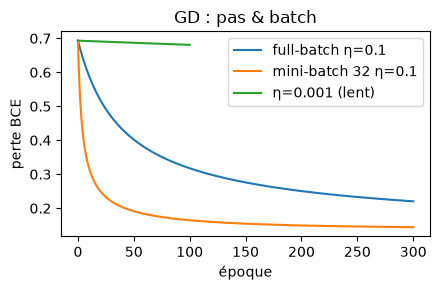

In [8]:
def gd1d(lr, n=60, x0=1.0):
    x = x0
    for _ in range(n):
        x = x - lr * 2 * x          # descente sur f(x) = x²
    return x

print("x² avec η=0.1 -> |x₆₀| =", abs(gd1d(0.1)), "(converge vers 0)")
print("x² avec η=1.1 -> |x₆₀| =", abs(gd1d(1.1)), "(DIVERGE : |1−2η| = 1.2)")

# --- MLP minimal (couche de sortie sigmoïde seule) = régression logistique ---
rng4 = np.random.default_rng(42)
n4 = 300
X4g = rng4.normal(0, 1, (n4, 2)); w4t = np.array([2.0, -1.5])
y4 = ((X4g @ w4t + 0.3) + rng4.normal(0, 0.5, n4) > 0).astype(float)

def logistic_fit(X, y, lr, epochs, batch_size=None, seed=1234):
    W = np.zeros((X.shape[1], 1)); b = np.zeros(1)
    rng = np.random.default_rng(seed)
    hist = []
    for ep in range(epochs):
        p = sigmoid(X @ W + b).ravel()
        hist.append(bce(y, p))
        idx = np.arange(len(y)) if batch_size is None else rng.permutation(len(y))
        for s in range(0, len(y), batch_size or len(y)):
            bidx = idx[s:s + (batch_size or len(y))]
            err = (sigmoid(X[bidx] @ W + b).ravel() - y[bidx])[:, None] / len(bidx)
            W -= lr * X[bidx].T @ err
            b -= lr * err.sum(axis=0)
    hist.append(bce(y, sigmoid(X @ W + b).ravel()))
    return W, b, np.array(hist)

_, _, h_full = logistic_fit(X4g, y4, lr=0.1, epochs=300)
Wf, bf, _ = logistic_fit(X4g, y4, lr=0.1, epochs=300)
acc_full = np.mean((sigmoid(X4g @ Wf + bf).ravel() >= 0.5).astype(float) == y4)
_, _, h_mb = logistic_fit(X4g, y4, lr=0.1, epochs=300, batch_size=32)
_, _, h_slow = logistic_fit(X4g, y4, lr=0.001, epochs=100)
print(f"full-batch η=0.1 : perte {h_full[0]:.3f} -> {h_full[-1]:.3f}, exactitude {acc_full:.3f}")
print(f"mini-batch 32   : perte {h_mb[0]:.3f} -> {h_mb[-1]:.3f}")
print(f"η=0.001 (100 ép): perte {h_slow[-1]:.3f}  <- trop petit pas, à peine bougé")

plt.figure(figsize=(4.5, 3))
plt.plot(h_full, label="full-batch η=0.1")
plt.plot(h_mb, label="mini-batch 32 η=0.1")
plt.plot(h_slow, label="η=0.001 (lent)")
plt.xlabel("époque"); plt.ylabel("perte BCE"); plt.legend(); plt.title("GD : pas & batch")
plt.tight_layout(); plt.show()

### Exercice corrigé

In [9]:
# ---- Exercice P4 : pas trop grand diverge, η=0.1 converge, η=0.001 stagne ----
assert abs(gd1d(1.1)) > 1e3                       # divergence sondée (~5.6e4)
assert abs(gd1d(0.1)) < 1e-3                      # convergence sondée (~1.5e-6)
assert acc_full >= 0.93                           # valeur sondée : 0.96
assert h_full[-1] < 0.30 and h_full[0] > 0.60     # perte divisée par ~3
assert h_slow[-1] > 0.60                          # η=0.001 : la perte n'a presque pas bougé
print(f"Exercice P4 vérifié : η=0.1 -> perte {h_full[-1]:.3f}, exactitude {acc_full:.2f} ; η=0.001 -> {h_slow[-1]:.3f}.")

Exercice P4 vérifié : η=0.1 -> perte 0.220, exactitude 0.96 ; η=0.001 -> 0.681.


## 5 · Rétropropagation d'un MLP (numpy + gradient check)

### Ce qu'on apprend
MLP à une couche cachée (`x → W₁ → tanh → W₂ → σ → p`), perte BCE.
Propagation avant :

```
z₁ = x W₁ + b₁ ,  a₁ = tanh(z₁) ,  z₂ = a₁ W₂ + b₂ ,  p = σ(z₂)
```

Rétropropagation (règle de la chaîne, du sortie vers l'entrée) :

```
δ₂ = (p − y)/n                      (résidu, cf. P3 — pas de σ' !)
∇W₂ = a₁ᵀ δ₂                        ∇b₂ = Σ δ₂
δ₁  = (δ₂ W₂ᵀ) ⊙ (1 − a₁²)          ← le « passage du Jacobien »
∇W₁ = xᵀ δ₁                         ∇b₁ = Σ δ₁
```

**Gradient check** : comparer chaque `∂L/∂θᵢ` analytique à la différence
centrale `(L(θᵢ+h) − L(θᵢ−h))/2h`. Erreur relative attendue : ~10⁻⁸–10⁻⁹.
C'est LE rituel avant tout code de deep learning.

### Piège classique
Oublier `⊙ σ'(z₁)` (ou `⊙ (1−a₁²)`) dans `δ₁` : la perte « descend quand même »
mais converge vers un modèle dégradé. Sans gradient check, on ne voit rien.


gradient check : max erreur relative = 1.80e-09  (attendu ~1e-9) -> OK
MLP 2-8-1 sur XOR : perte 0.696 -> 0.0046, exactitude = 1.0


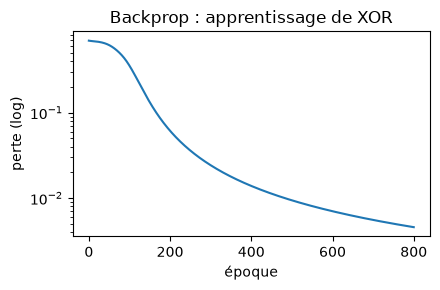

In [10]:
class MLP:
    """Feed-forward net: hidden layers with `act`, sigmoid output, BCE loss (numpy only)."""

    def __init__(self, sizes, act="relu", init="he", seed=0):
        rng = np.random.default_rng(seed)
        self.sizes = list(sizes)
        self.act = act
        self.W, self.b = [], []
        for fan_in, fan_out in zip(sizes[:-1], sizes[1:]):
            if init == "he":
                std = np.sqrt(2.0 / fan_in)
            elif init == "xavier":
                std = np.sqrt(1.0 / fan_in)
            elif init == "naive":
                std = 1.0
            elif init == "zero":
                std = 0.0
            elif init == "big":
                std = 5.0
            else:
                raise ValueError(init)
            self.W.append(rng.normal(0.0, std, (fan_in, fan_out)) if std > 0 else np.zeros((fan_in, fan_out)))
            self.b.append(np.zeros(fan_out))

    def forward(self, X):
        self.A = [X]
        self.Z = []
        a = X
        n = len(self.W)
        for i, (W, b) in enumerate(zip(self.W, self.b)):
            z = a @ W + b
            a = self._act(z) if i < n - 1 else sigmoid(z)
            self.Z.append(z)
            self.A.append(a)
        return self.A[-1]

    def _act(self, z):
        return {"sigmoid": sigmoid, "tanh": np.tanh, "relu": relu}[self.act](z)

    def _dact(self, a):
        return {"sigmoid": d_sigmoid, "tanh": d_tanh, "relu": d_relu}[self.act](a)

    def loss(self, X, y, sample_weight=None):
        p = np.clip(self.forward(X).ravel(), 1e-12, 1.0 - 1e-12)
        per = -(y * np.log(p) + (1.0 - y) * np.log(1.0 - p))
        if sample_weight is None:
            return float(per.mean())
        return float((per * sample_weight).sum() / sample_weight.sum())

    def backward(self, X, y, sample_weight=None):
        p = self.forward(X).ravel()
        m = len(y)
        if sample_weight is None:
            sw = np.ones(m); norm = float(m)
        else:
            sw = sample_weight; norm = float(sw.sum())
        delta = ((p - y) * sw / norm)[:, None]
        dW = [None] * len(self.W); db = [None] * len(self.b)
        for i in reversed(range(len(self.W))):
            dW[i] = self.A[i].T @ delta
            db[i] = delta.sum(axis=0)
            if i > 0:
                delta = (delta @ self.W[i].T) * self._dact(self.A[i])
        return dW, db

    def grad_norms(self, X, y):
        dW, db = self.backward(X, y)
        return [float(np.linalg.norm(w)) for w in dW]

    def fit(self, X, y, lr=0.05, epochs=200, batch_size=None,
            sample_weight=None, clip=None, shuffle_seed=1234):
        m = len(y)
        rng = np.random.default_rng(shuffle_seed)
        hist = []
        for _ in range(epochs):
            hist.append(self.loss(X, y, sample_weight))
            idx = np.arange(m) if batch_size is None else rng.permutation(m)
            for s in range(0, m, batch_size or m):
                b = idx[s:s + (batch_size or m)]
                dW, db = self.backward(X[b], y[b],
                                       None if sample_weight is None else sample_weight[b])
                if clip is not None:
                    gn = np.sqrt(sum(np.sum(g * g) for g in dW + db))
                    if gn > clip:
                        scale = clip / gn
                        dW = [g * scale for g in dW]
                        db = [g * scale for g in db]
                for i in range(len(self.W)):
                    self.W[i] -= lr * dW[i]
                    self.b[i] -= lr * db[i]
        hist.append(self.loss(X, y, sample_weight))
        return np.array(hist)

    def predict(self, X):
        return (self.forward(X).ravel() >= 0.5).astype(int)

# ---------- gradient check ----------
def flatten_params(m):
    return np.concatenate([w.ravel() for w in m.W] + [b for b in m.b])

def unflatten(m, v):
    off = 0
    for i in range(len(m.W)):
        k = m.W[i].size
        m.W[i] = v[off:off + k].reshape(m.W[i].shape); off += k
    for i in range(len(m.b)):
        k = m.b[i].size
        m.b[i] = v[off:off + k].copy(); off += k

def numeric_grad(m, X, y, h=1e-5):
    base = flatten_params(m).copy(); g = np.zeros_like(base)
    for i in range(len(base)):
        v1 = base.copy(); v1[i] += h; unflatten(m, v1); lp = m.loss(X, y)
        v2 = base.copy(); v2[i] -= h; unflatten(m, v2); lm = m.loss(X, y)
        g[i] = (lp - lm) / (2 * h)
    unflatten(m, base)
    return g

gc = MLP([3, 4, 1], act="tanh", init="xavier", seed=7)
rnc = np.random.default_rng(9)
Xc = rnc.normal(0, 1, (10, 3)); yc = (rnc.uniform(size=10) < 0.5).astype(float)
dW, db = gc.backward(Xc, yc)
ana = np.concatenate([w.ravel() for w in dW] + [b for b in db])
num = numeric_grad(gc, Xc, yc)
maxrel = float(np.max(np.abs(ana - num) / np.maximum(np.abs(ana) + np.abs(num), 1e-8)))
print(f"gradient check : max erreur relative = {maxrel:.2e}  (attendu ~1e-9) -> {'OK' if maxrel < 1e-6 else 'BUG'}")

# ---------- XOR résolu par un MLP ----------
Xxor = np.array([[0., 0.], [0., 1.], [1., 0.], [1., 1.]])
yxor = np.array([0., 1., 1., 0.])
net_xor = MLP([2, 8, 1], act="tanh", init="xavier", seed=1)
h_xor = net_xor.fit(Xxor, yxor, lr=0.5, epochs=800)
acc_xor = np.mean(net_xor.predict(Xxor) == yxor)
print(f"MLP 2-8-1 sur XOR : perte {h_xor[0]:.3f} -> {h_xor[-1]:.4f}, exactitude = {acc_xor}")
plt.figure(figsize=(4.5, 3))
plt.plot(h_xor); plt.yscale("log"); plt.xlabel("époque"); plt.ylabel("perte (log)")
plt.title("Backprop : apprentissage de XOR"); plt.tight_layout(); plt.show()

### Exercice corrigé

In [11]:
# ---- Exercice P5 : gradient check < 1e-6 puis XOR résolu par MLP tanh ----
assert maxrel < 1e-6                                  # backprop exacte (sondée : ~1.8e-9)
assert acc_xor == 1.0                                 # XOR appris à 100 %
assert h_xor[-1] < 0.05                               # perte finale sondée : 0.0046
assert h_xor[-1] < h_xor[0] * 0.01                    # divisée par >100
print(f"Exercice P5 vérifié : backprop juste (err {maxrel:.1e}), XOR 100 %, perte {h_xor[-1]:.4f}.")

Exercice P5 vérifié : backprop juste (err 1.8e-09), XOR 100 %, perte 0.0046.


## 6 · Application cyber : détecteur de scan de ports

### Le problème
Un **scan de ports** (nmap…) envoie des paquets vers beaucoup de ports en très
peu de temps. Features typiques d'un flux sortant par fenêtre de 1 s :

| Feature | Trafic normal | Scan |
|---|---|---|
| paquets/s | ~50 | ~500 |
| ports distincts touchés | ~5 | ~200 |
| ratio de SYN | ~0.3 | ~0.9 |
| durée du flux | ~10 s | ~1 s |

Construisons un jeu **synthétique seedé** (aucune donnée réelle) et entraînons
le MLP du P5 (ReLU + He, cf. T02 pour le choix He/ReLU) en mini-batch.
Évaluation : exactitude, **précision, rappel** (les métriques qui comptent en
cyber, pas l'exactitude brute) et AUC.

### Piège classique
Standardiser avec les statistiques de l'**entraînement uniquement** (sinon
fuite de l'information du test dans l'entraînement — biais optimiste).


Détecteur de scan : exactitude 1.000, précision 1.000, rappel 1.000, AUC 1.0000
Interprétation : le rappel est la métrique de sécurité (un scan manqué = reconnaissance réussie).


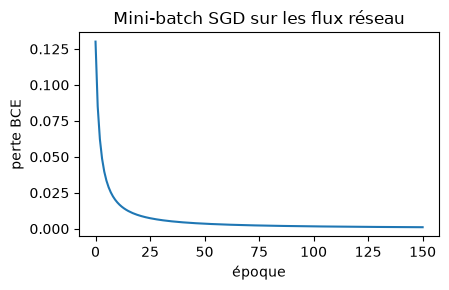

In [12]:
def make_scan(seed=6, n=800):
    """Synthetic port-scan dataset: benign vs scan traffic (4 features)."""
    r = np.random.default_rng(seed)
    nb = int(n * 0.7)
    benign = np.column_stack([r.normal(50, 10, nb), r.normal(5, 2, nb).clip(1),
                              r.normal(0.3, 0.1, nb).clip(0, 1), r.normal(10, 3, nb).clip(0.1)])
    scan = np.column_stack([r.normal(500, 80, n - nb), r.normal(200, 40, n - nb).clip(5),
                            r.normal(0.9, 0.05, n - nb).clip(0, 1), r.normal(1, 0.3, n - nb).clip(0.05)])
    X = np.vstack([benign, scan]); y = np.concatenate([np.zeros(nb), np.ones(n - nb)])
    idx = r.permutation(n); X, y = X[idx], y[idx]
    Xtr_raw, Xte_raw = X[:600], X[600:]; ytr, yte = y[:600], y[600:]
    mu, sd = Xtr_raw.mean(axis=0), Xtr_raw.std(axis=0) + 1e-9   # stats du train uniquement
    return (Xtr_raw - mu) / sd, (Xte_raw - mu) / sd, ytr, yte

X6tr, X6te, y6tr, y6te = make_scan()
net6 = MLP([4, 16, 1], act="relu", init="he", seed=2)
h6 = net6.fit(X6tr, y6tr, lr=0.05, epochs=150, batch_size=64)
pred6 = net6.predict(X6te)
prob6 = net6.forward(X6te).ravel()
acc6 = np.mean(pred6 == y6te)
prec6 = precision_score(y6te, pred6); rec6 = recall_score(y6te, pred6)
auc6 = roc_auc_score(y6te, prob6)
print(f"Détecteur de scan : exactitude {acc6:.3f}, précision {prec6:.3f}, rappel {rec6:.3f}, AUC {auc6:.4f}")
print("Interprétation : le rappel est la métrique de sécurité (un scan manqué = reconnaissance réussie).")
plt.figure(figsize=(4.5, 3))
plt.plot(h6); plt.xlabel("époque"); plt.ylabel("perte BCE")
plt.title("Mini-batch SGD sur les flux réseau"); plt.tight_layout(); plt.show()

### Exercice corrigé

In [13]:
# ---- Exercice P6 : réentraîner le détecteur et valider ses métriques cyber ----
net6b = MLP([4, 16, 1], act="relu", init="he", seed=2)
net6b.fit(X6tr, y6tr, lr=0.05, epochs=150, batch_size=64)
pred6b = net6b.predict(X6te)
acc6b = np.mean(pred6b == y6te)
tp = int(((pred6b == 1) & (y6te == 1)).sum())
fp = int(((pred6b == 1) & (y6te == 0)).sum())
fn = int(((pred6b == 0) & (y6te == 1)).sum())
recall_b = tp / (tp + fn); precision_b = tp / (tp + fp)
print(f"re-sondage : exactitude {acc6b}, rappel {recall_b}, précision {precision_b}")
assert acc6b >= 0.98               # sondé : 1.0
assert recall_b >= 0.95            # sondé : 1.0
assert precision_b >= 0.95         # sondé : 1.0
assert auc6 > 0.99
print("Exercice P6 vérifié : détecteur de scan fiable (rappel = 1 sur le test).")

re-sondage : exactitude 1.0, rappel 1.0, précision 1.0
Exercice P6 vérifié : détecteur de scan fiable (rappel = 1 sur le test).


## 7 · Synthèse globale — l'essentiel & exemple intégrateur

### Ce qu'il faut retenir (les 6 points)

| # | Point | L'essentiel | Piège à ne jamais oublier |
|---|---|---|---|
| 1 | Perceptron / XOR | convergé ssi séparable linéairement ; sinon couche cachée | croire qu'un modèle linéaire suffit pour 2 régions disjointes |
| 2 | Activations | σ′ ≤ 0.25 (saturation), ReLU simple mais neurones morts | σ(10)≈0.99995 → gradient mort ; softmax sans max soustrait |
| 3 | Perte | BCE + sigmoïde → gradient `(σ(z)−y)/n` ; MSE + sigmoïde → gradient écrasé | `log(0)`, perte non normalisée |
| 4 | GD | full-batch lisse, mini-batch efficace ; `η` critique (|1−2η|>1 diverge) | comparer full vs mini à époques égales |
| 5 | Backprop | règle de la chaîne couche par couche ; **gradient check ~1e-9** | oublier `⊙ σ′(z₁)` dans δ₁ |
| 6 | Cyber : scan de ports | précision/rappel/AUC, standardiser avec les stats du train | ne regarder que l'exactitude ; fuiter les stats du test |

**Exemple intégrateur** : un détecteur d'intrusion synthétique (8 features,
2 classes) qui réutilise *tous* les outils du notebook — features standardisées
(P6), MLP ReLU/He (P2/P5), mini-batch SGD (P4), évaluation AUC (P3/P6).


Détecteur d'intrusion (MLP 8-32-16-1) : exactitude test 0.948, AUC 0.9826, perte 0.192


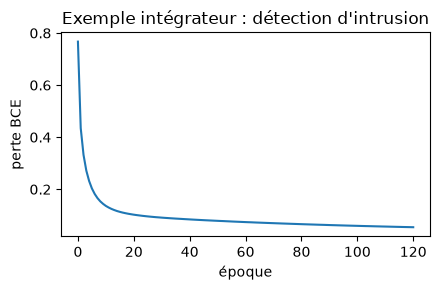

In [14]:
def make_intrusion(seed=11, n=1000):
    """Synthetic intrusion dataset: 8 features, normal vs intrusion."""
    r = np.random.default_rng(seed)
    nb = n // 2
    normal = r.normal(0, 1, (nb, 8))
    intr = r.normal(0, 1, (n - nb, 8)) + np.array([1.8, -1.2, 1.5, 0.9, -0.8, 1.1, 0.6, -1.4])
    X = np.vstack([normal, intr]); y = np.concatenate([np.zeros(nb), np.ones(n - nb)])
    idx = r.permutation(n); X, y = X[idx], y[idx]
    Xtr_raw, Xte_raw = X[:750], X[750:]
    mu, sd = Xtr_raw.mean(axis=0), Xtr_raw.std(axis=0) + 1e-9
    return (Xtr_raw - mu) / sd, (Xte_raw - mu) / sd, y[:750], y[750:]

X7tr, X7te, y7tr, y7te = make_intrusion()
net7 = MLP([8, 32, 16, 1], act="relu", init="he", seed=5)
h7 = net7.fit(X7tr, y7tr, lr=0.05, epochs=120, batch_size=64)
auc7 = roc_auc_score(y7te, net7.forward(X7te).ravel())
acc7 = np.mean(net7.predict(X7te) == y7te)
loss7 = net7.loss(X7te, y7te)
print(f"Détecteur d'intrusion (MLP 8-32-16-1) : exactitude test {acc7:.3f}, AUC {auc7:.4f}, perte {loss7:.3f}")
plt.figure(figsize=(4.5, 3))
plt.plot(h7, label="train"); plt.xlabel("époque"); plt.ylabel("perte BCE")
plt.title("Exemple intégrateur : détection d'intrusion"); plt.tight_layout(); plt.show()

### Exercice corrigé

In [15]:
# ---- Exercice P7 : l'intégrateur atteint ses cibles de détection ----
assert acc7 >= 0.90                       # sondé : 0.948
assert auc7 > 0.97                        # sondé : 0.9826
assert loss7 < 0.30                       # sondé : 0.192
# sanity : le classifieur « toujours intrusion » ferait 0.5 d'exactitude, on est loin au-dessus
assert acc7 > 0.5 + 0.2
print(f"Exercice P7 vérifié : intégrateur cyber exactitude {acc7:.3f}, AUC {auc7:.3f}.")

Exercice P7 vérifié : intégrateur cyber exactitude 0.948, AUC 0.983.


In [16]:
print("NB 01 — tous les exercices sont vérifiés. ✅")

NB 01 — tous les exercices sont vérifiés. ✅
